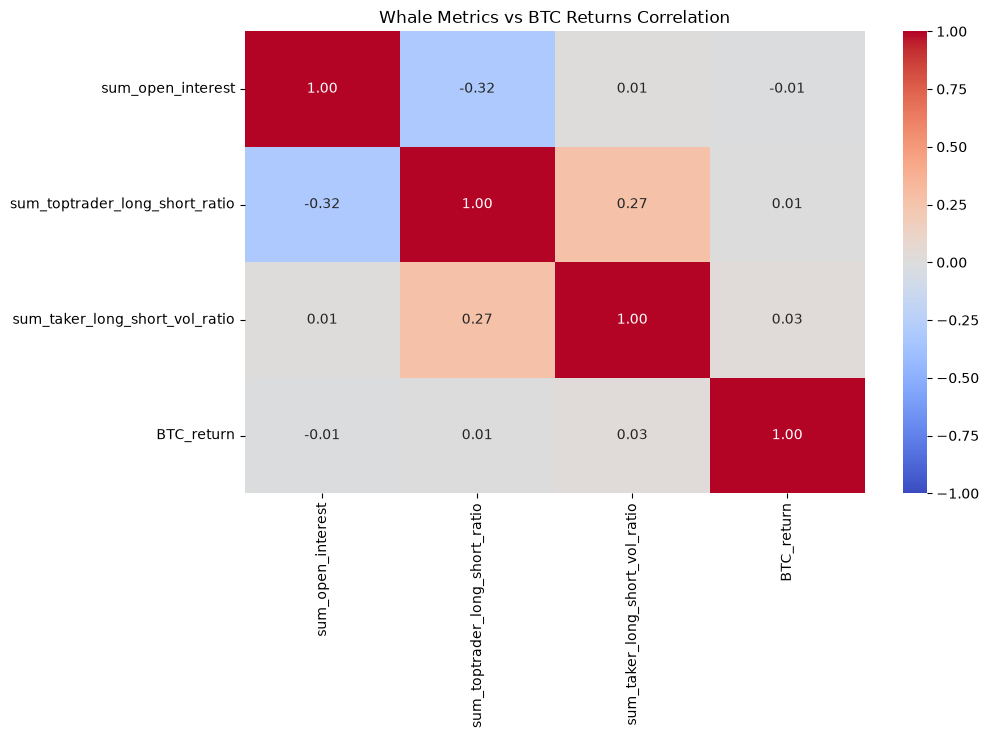

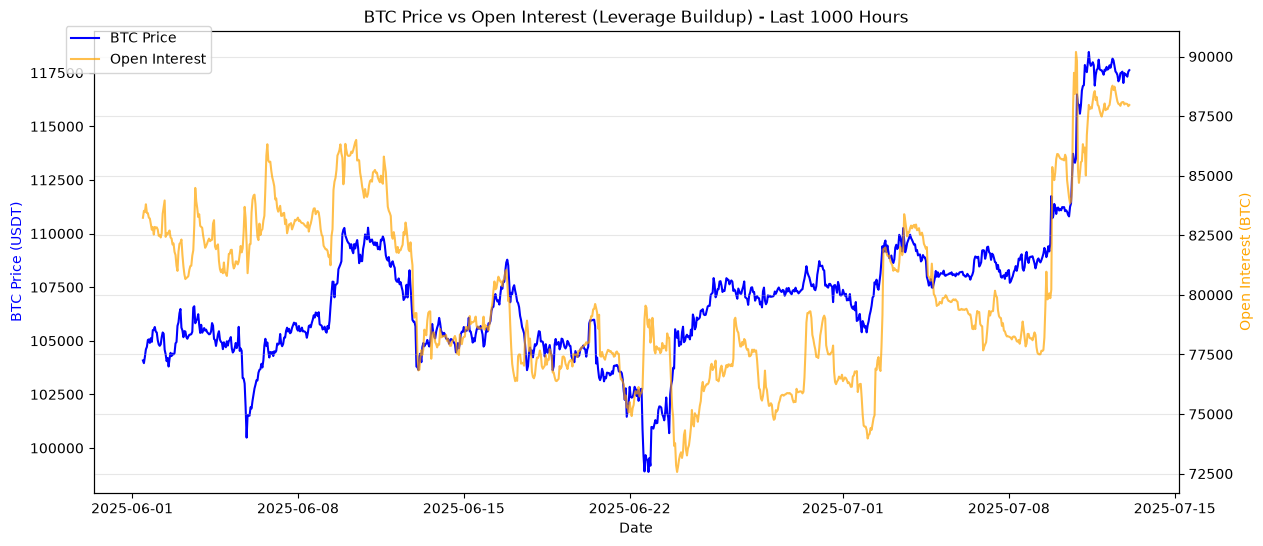

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


processed_path = r"E:\Innovus\Documents\Agentic-AI-Based-Market-Intelligence-Framework-For-Bitcoin-and-Ethereum-Trading\Vibhu Kalpitha\data\02_processed\internal_cleaned_1h.csv"
df = pd.read_csv(processed_path)
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# 2. Correlation: Whale Metrics vs BTC Returns

df['BTC_return'] = df['BTC_close'].pct_change()
whale_cols = ['sum_open_interest', 'sum_toptrader_long_short_ratio', 'sum_taker_long_short_vol_ratio', 'BTC_return']

corr = df[whale_cols].dropna().corr()
plt.figure(figsize=(10, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("Whale Metrics vs BTC Returns Correlation")
plt.show()

# 3. Open Interest vs BTC Price Trend 

fig, ax1 = plt.subplots(figsize=(14, 6))
ax2 = ax1.twinx()

subset = df.iloc[-1000:] 
ax1.plot(subset.index, subset['BTC_close'], color='blue', label='BTC Price')
ax2.plot(subset.index, subset['sum_open_interest'], color='orange', alpha=0.7, label='Open Interest')

ax1.set_xlabel('Date')
ax1.set_ylabel('BTC Price (USDT)', color='blue')
ax2.set_ylabel('Open Interest (BTC)', color='orange')
plt.title("BTC Price vs Open Interest (Leverage Buildup) - Last 1000 Hours")
fig.legend(loc="upper left", bbox_to_anchor=(0.1,0.9))
plt.grid(True, alpha=0.3)
plt.show()